In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

# Task 1

(392, 9)


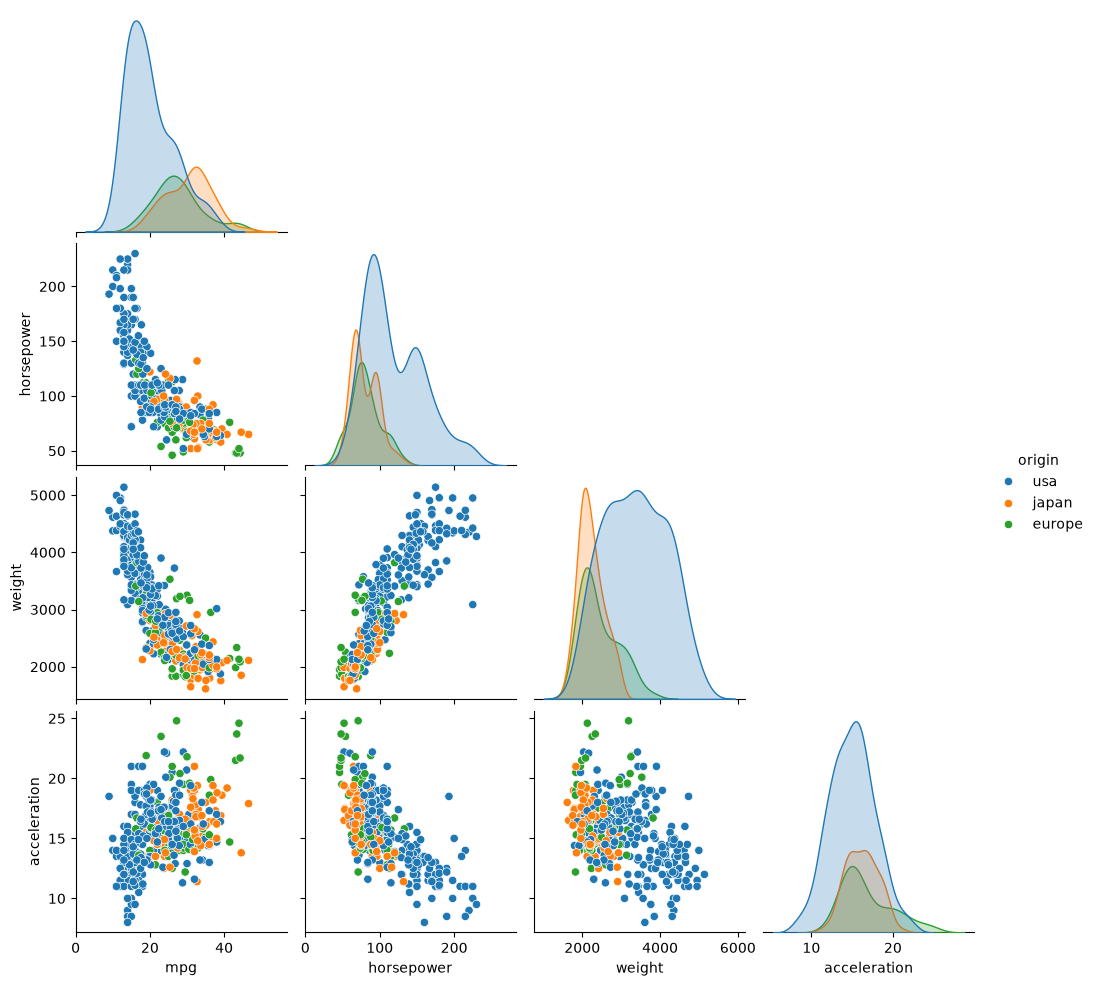

In [2]:
mpg = sns.load_dataset('mpg')
mpg = mpg.dropna()
print(mpg.shape)

g = sns.pairplot(mpg[['mpg', 'horsepower', 'weight', 'acceleration', 'origin']], hue='origin', corner=True)
g.savefig('mpg_pairplot.png')
plt.show()

# Task 2

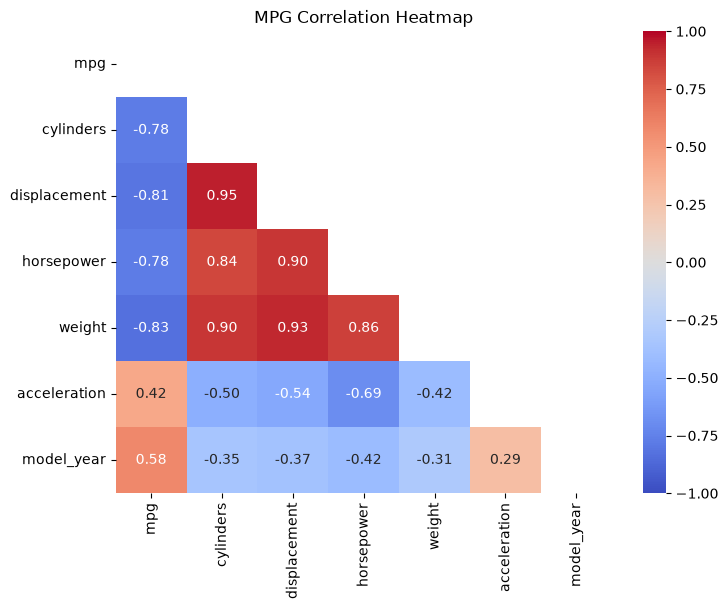

Most negatively correlated with mpg: weight


In [3]:
corr = mpg.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('MPG Correlation Heatmap')
fig.savefig('mpg_corr.png')
plt.show()

print("Most negatively correlated with mpg:", corr['mpg'].drop('mpg').idxmin())

# Task 3

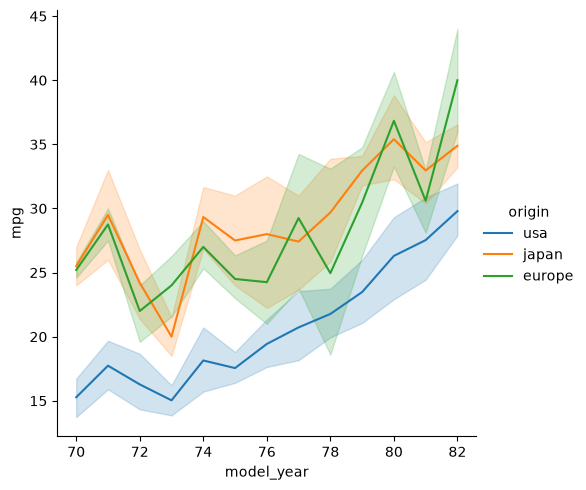

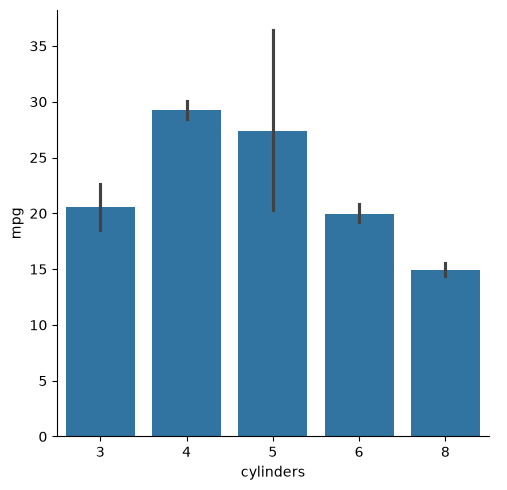

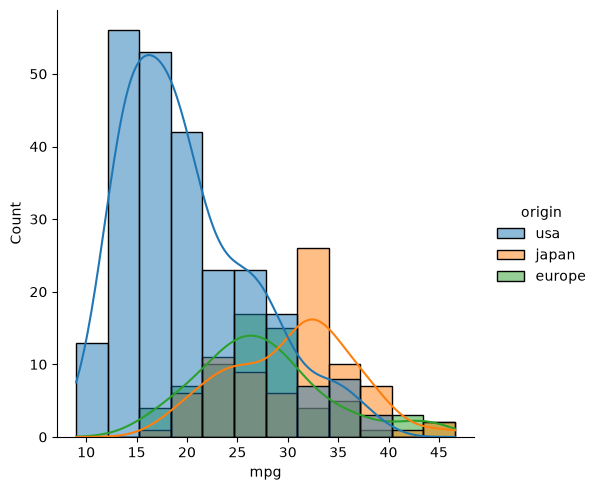

In [4]:
g1 = sns.relplot(data=mpg, x='model_year', y='mpg', hue='origin', kind='line')
g1.savefig('mpg_relplot.png')

g2 = sns.catplot(data=mpg, x='cylinders', y='mpg', kind='bar', errorbar=('ci', 95))
g2.savefig('mpg_catplot.png')

g3 = sns.displot(data=mpg, x='mpg', hue='origin', kde=True)
g3.savefig('mpg_displot.png')
plt.show()

# Task 4

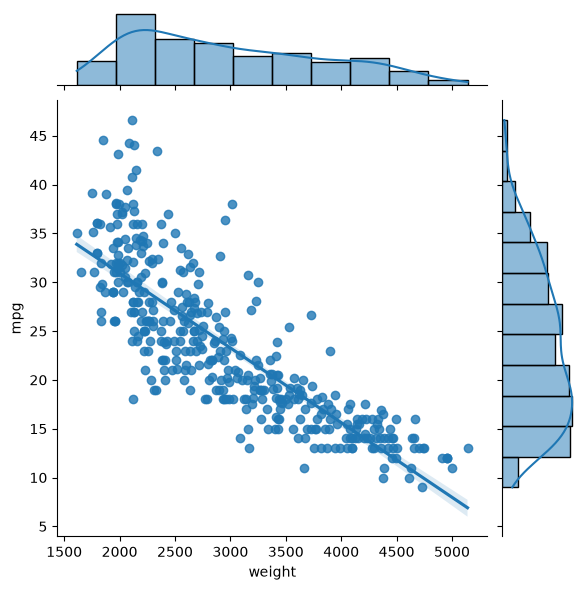

[WindowsPath('mpg_catplot.png'), WindowsPath('mpg_corr.png'), WindowsPath('mpg_displot.png'), WindowsPath('mpg_joint.png'), WindowsPath('mpg_pairplot.png'), WindowsPath('mpg_relplot.png')]


In [5]:
g = sns.jointplot(data=mpg, x='weight', y='mpg', kind='reg')
g.savefig('mpg_joint.png')
plt.show()

mpg_files = sorted(Path('.').glob('mpg_*.png'))
print(mpg_files)
assert len(mpg_files) == 6